In [1]:
import numpy as np
import pandas as pd
from fractions import Fraction
import matplotlib
import matplotlib.pyplot as plt
import scipy
from scipy import stats

### Question 1
Which is more probable when rolling 2 six-sided dice: rolling snake eyes (two ones) or rolling sevens (dice sum to seven)? What is the ratio of the probabilities?

It is more probable to roll sevens (P(7) = 6/36) compared to rolling snake eyes (P(2) = 1/36)). The ratio of the probabilities if 1:6 for the probability of rolling snake eyes to the probability of rolling sevens

### Question 2
Following what we did in class show how to use the convolution operator to determine the probability of the sum of 2 six sided dice. Do both analytically (math & counting) and numerically (computer program). Beware the implicit definition of the values (x-axis on histogram).

$$P_{A+B}(x) = \sum_{z}{P_A(z)P_B(x-z)} = P_A(x) \ast P_B(x)$$


$P_A(z) = P_B(z) = \frac{1}{6}$ where $z  \in \{1, 2, 3, 4, 5, 6\}$

<br>

 

$P_{A+B}(2) = P_A(1)P_B(2-1) = (\frac{1}{6})(\frac{1}{6})$

$P_{A+B}(3) = P_A(1)P_B(3-1) + P_A(2)P_B(3-2) = (\frac{1}{6})(\frac{1}{6}) + (\frac{1}{6})(\frac{1}{6})$

$P_{A+B}(4) = P_A(1)P_B(4-1) + P_A(2)P_B(4-2) + P_A(3)P_B(4-3) = (\frac{1}{6})(\frac{1}{6}) + (\frac{1}{6})(\frac{1}{6}) + (\frac{1}{6})(\frac{1}{6})$

$P_{A+B}(5) = P_A(1)P_B(5-1) + P_A(2)P_B(5-2) + P_A(3)P_B(5-3) + P_A(4)P_B(5-4)= (\frac{1}{6})(\frac{1}{6}) + (\frac{1}{6})(\frac{1}{6}) + (\frac{1}{6})(\frac{1}{6}) + (\frac{1}{6})(\frac{1}{6})$

$P_{A+B}(6) = P_A(1)P_B(6-1) + P_A(2)P_B(6-2) + P_A(3)P_B(6-3) + P_A(4)P_B(6-4) + P_A(4)P_B(6-5)= (\frac{1}{6})(\frac{1}{6}) + (\frac{1}{6})(\frac{1}{6}) + (\frac{1}{6})(\frac{1}{6}) + (\frac{1}{6})(\frac{1}{6}) + (\frac{1}{6})(\frac{1}{6})$

$P_{A+B}(7) = P_A(1)P_B(7-1) + P_A(2)P_B(7-2) + P_A(3)P_B(7-3) + P_A(4)P_B(7-4) + P_A(5)P_B(7-5) +  P_A(6)P_B(7-6)= (\frac{1}{6})(\frac{1}{6}) + (\frac{1}{6})(\frac{1}{6}) + (\frac{1}{6})(\frac{1}{6}) + (\frac{1}{6})(\frac{1}{6}) + (\frac{1}{6})(\frac{1}{6}) + (\frac{1}{6})(\frac{1}{6})$

$P_{A+B}(8) = P_A(2)P_B(8-2) + P_A(3)P_B(8-3) + P_A(4)P_B(8-4) + P_A(5)P_B(8-5) +  P_A(6)P_B(8-6)= (\frac{1}{6})(\frac{1}{6}) + (\frac{1}{6})(\frac{1}{6}) + (\frac{1}{6})(\frac{1}{6}) + (\frac{1}{6})(\frac{1}{6}) + (\frac{1}{6})(\frac{1}{6})$

$P_{A+B}(9) = P_A(3)P_B(9-3) + P_A(4)P_B(9-4) + P_A(5)P_B(9-5) +  P_A(6)P_B(9-6)= (\frac{1}{6})(\frac{1}{6}) + (\frac{1}{6})(\frac{1}{6}) + (\frac{1}{6})(\frac{1}{6}) + (\frac{1}{6})(\frac{1}{6})$

$P_{A+B}(10) = P_A(4)P_B(10-4) + P_A(5)P_B(10-5) +  P_A(6)P_B(10-6)= (\frac{1}{6})(\frac{1}{6}) + (\frac{1}{6})(\frac{1}{6}) + (\frac{1}{6})(\frac{1}{6})$

$P_{A+B}(11) = P_A(5)P_B(11-5) +  P_A(6)P_B(11-6)= (\frac{1}{6})(\frac{1}{6}) + (\frac{1}{6})(\frac{1}{6})$

$P_{A+B}(12) = P_A(5)P_B(11-5) +  P_A(6)P_B(12-6)= (\frac{1}{6})(\frac{1}{6})$

In [2]:
sum_table1 = {
    "Sum": [2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12],
    "Outcomes": ["(1, 1)", "(1, 2) (2, 1)", "(1, 3) (2, 2) (3, 1)", "(1, 4) (2, 3) (3, 2) (4, 1)", 
                 "(1, 5) (2, 4) (3, 3) (4, 2) (5, 1)", "(1, 6) (2, 5) (3, 4) (4, 3) (5, 2) (6, 1)",
                 "(2, 6) (3, 5) (4, 4) (5, 3) (2, 6)", "(3, 6) (4, 5) (5, 4) (6, 3)", 
                 "(4, 6) (5, 5) (6, 4)", "(5, 6) (5, 6)", "(6, 6)"],
    "Probability": [Fraction('1/36'),Fraction('2/36'), Fraction('3/36'), Fraction('4/36'), 
                    Fraction('5/36'), Fraction('6/36'), Fraction('5/36'), Fraction('4/36'), 
                    Fraction('3/36'), Fraction('2/36'), Fraction('1/36')]
}

sum_tbl1 = pd.DataFrame(sum_table1)
sum_tbl1

,Sum,Outcomes,Probability
0,2,"(1, 1)",1/36
1,3,"(1, 2) (2, 1)",1/18
2,4,"(1, 3) (2, 2) (3, 1)",1/12
3,5,"(1, 4) (2, 3) (3, 2) (4, 1)",1/9
4,6,"(1, 5) (2, 4) (3, 3) (4, 2) (5, 1)",5/36
5,7,"(1, 6) (2, 5) (3, 4) (4, 3) (5, 2) (6, 1)",1/6
6,8,"(2, 6) (3, 5) (4, 4) (5, 3) (2, 6)",5/36
7,9,"(3, 6) (4, 5) (5, 4) (6, 3)",1/9
8,10,"(4, 6) (5, 5) (6, 4)",1/12
9,11,"(5, 6) (5, 6)",1/18


In [3]:
sums = np.array([2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12])

p_dice = np.array([1/6, 1/6, 1/6, 1/6, 1/6, 1/6])
p_sum = np.convolve(p_dice, p_dice)

In [4]:
sum_table2 = {
    "Sum": sums,
    "Probability": p_sum
}

sum_tbl2 = pd.DataFrame(sum_table2)
sum_tbl2

,Sum,Probability
0,2,0.027778
1,3,0.055556
2,4,0.083333
3,5,0.111111
4,6,0.138889
5,7,0.166667
6,8,0.138889
7,9,0.111111
8,10,0.083333
9,11,0.055556


### Question 3
Calculate the mean and the variance of the distribution in problem 2

$\mu =E(X)=\sum x P(x)$

$\sigma ^2=\left [ \sum x^2 P(x)\right ]-\mu ^2$

In [5]:
sum_mean = sum(sums * p_sum)
f"The mean of the distribution in problem 2 is {sum_mean}."

'The mean of the distribution in problem 2 is 7.0.'

In [6]:
sum_var = sum((sums ** 2) * p_sum) - (sum_mean ** 2)
f'The variance of the distribution in problem 2 is {sum_var:.4f}.'

'The variance of the distribution in problem 2 is 5.8333.'

### Question 4
Repeat 2, and graph the average of 10 dice. Is this is a Gaussian distribution? Explain in depth.

In [7]:
p_dice10 = p_dice
for _ in range(9):
    p_dice10 = np.convolve(p_dice10, p_dice)

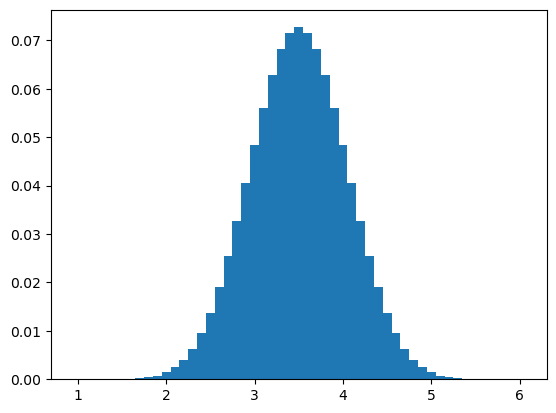

In [8]:
fig, ax = plt.subplots(1, 1)
x_avg = np.linspace(10, 60, 51) / 10
ax.bar(x_avg, p_dice10, width = .1, label = "Average of 10 dice")
plt.show()

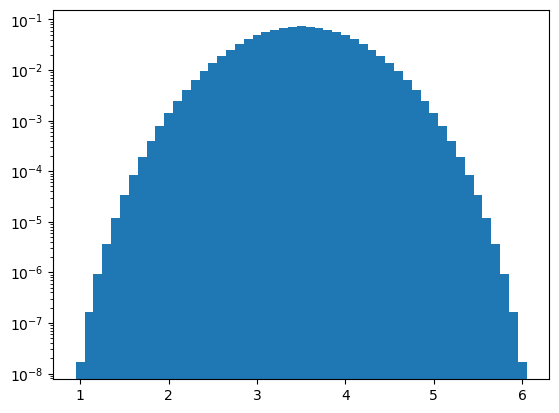

In [9]:
fig, ax = plt.subplots(1, 1)
plt.yscale('log')
x_avg = np.linspace(10, 60, 51) / 10
ax.bar(x_avg, p_dice10, width = .1, label = "Average of 10 dice")
plt.show()

No? While it looks Gaussian, including in log scale, a Gaussian distribution is a continuous probability distribution, while this is a discrete probability distribution. It's also bounded between 1 and 6; a Gaussian distribution is not bounded.

### Question 5
Show that the sum and average of an initially Gaussian distribution is also a Gaussian (can be analytic or numerical). How does the standard deviation of the resulting sum or average Gaussian change? This is a hugely important result. Explore what this means for integrating a signal over time. How does this explain error analysis and error propagation you have done in previous classes (classes that assumed Gaussian errors)?

In [10]:
mu1 = 5
sigma1 = 3
mu2 = -4
sigma2 = 0.5

G1 = np.random.normal(mu1, sigma1, 100000)
G2 = np.random.normal(mu2, sigma2, 100000)

G_sum = G1 + G2
G_avg = (G1 + G2) / 2


G_sum_exp_mu = mu1 + mu2
G_sum_calc_mu = np.mean(G_sum)

G_sum_exp_var = ((sigma1 ** 2) + (sigma2 ** 2))
G_sum_calc_var = np.var(G_sum)

G_avg_exp_mu = (mu1 + mu2) / 2
G_avg_calc_mu = np.mean(G_avg)

G_avg_exp_var = ((sigma1 ** 2) + (sigma2 ** 2)) / 4
G_avg_calc_var = np.var(G_avg)


print(f"For Sum, Expected Mean: {G_sum_exp_mu}. For Sum, Calculated Mean: {G_sum_calc_mu:.4f}.")
print(f"For Sum, Expected Variance: {G_sum_exp_var}. For Sum, Calculated Variance: {G_sum_calc_var:.4f}")

print(f"For Average, Expected Mean: {G_avg_exp_mu}. For Average, Calculated Mean: {G_avg_calc_mu:.4f}.")
print(f"For Average, Expected Variance: {G_avg_exp_var}. For Average, Calculated Variance: {G_avg_calc_var:.4f}")

For Sum, Expected Mean: 1. For Sum, Calculated Mean: 1.0130.
For Sum, Expected Variance: 9.25. For Sum, Calculated Variance: 9.1630
For Average, Expected Mean: 0.5. For Average, Calculated Mean: 0.5065.
For Average, Expected Variance: 2.3125. For Average, Calculated Variance: 2.2907


As you add measurements with error over time, the total error will increase in variability. If you average measurements with error over time, variability in the average error will go down.

Binx

Binx

Binx